<a href="https://colab.research.google.com/github/RadhikaPande5/drone-imagery-assessment/blob/main/drone_damage_assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install segmentation-models-pytorch albumentations \
    opencv-python-headless matplotlib scikit-learn tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.5 MB/s eta 0:00:00


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
from google.colab import files

uploaded = files.upload()

Saving 10787_lab.png to 10787_lab.png


In [4]:
import os

print("Original image exists:", os.path.exists("/content/10787.jpg"))
print("Color mask exists:", os.path.exists("/content/10787_lab.png"))

Original image exists: True
Color mask exists: True


Original image shape: (3000, 4000, 3)
Mask shape: (1024, 1024, 3)
Mask data type: uint8


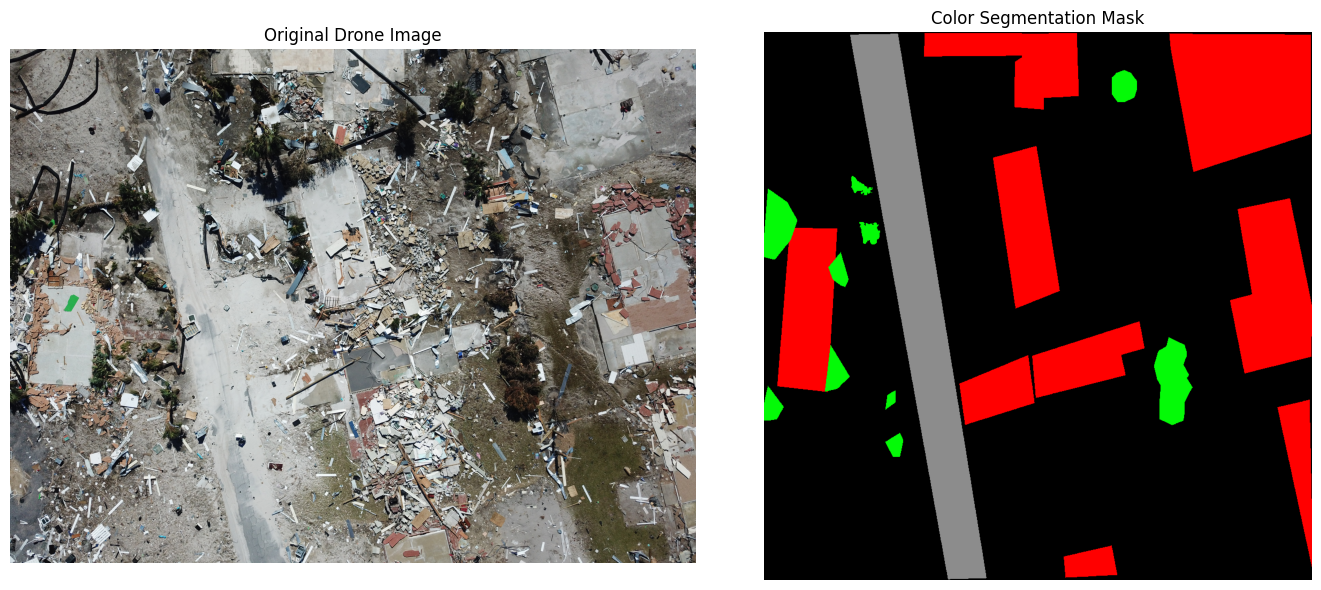

In [6]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Load the uploaded original image and mask
image = Image.open("/content/10787.jpg").convert("RGB")
mask = Image.open("/content/10787_lab.png")

image_np = np.array(image)
mask_np = np.array(mask)

print("Original image shape:", image_np.shape)
print("Mask shape:", mask_np.shape)
print("Mask data type:", mask_np.dtype)

# Display them side by side
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(image_np)
ax[0].set_title("Original Drone Image")
ax[0].axis("off")

ax[1].imshow(mask_np)
ax[1].set_title("Color Segmentation Mask")
ax[1].axis("off")

plt.tight_layout()
plt.show()

In [7]:
from PIL import Image
import os

pairs = [
    ("/content/10787.jpg", "/content/10787_lab.png"),
]

for image_path, mask_path in pairs:
    image = Image.open(image_path)
    mask = Image.open(mask_path)

    print("Image:", os.path.basename(image_path))
    print("  Original dimensions (W, H):", image.size)
    print("Mask:", os.path.basename(mask_path))
    print("  Mask dimensions (W, H):", mask.size)
    print("  Mask mode:", mask.mode)

Image: 10787.jpg
  Original dimensions (W, H): (4000, 3000)
Mask: 10787_lab.png
  Mask dimensions (W, H): (1024, 1024)
  Mask mode: RGB


In [9]:
from PIL import Image
import numpy as np

mask = np.array(Image.open("/content/10787_lab.png").convert("RGB"))

colors, counts = np.unique(
    mask.reshape(-1, 3),
    axis=0,
    return_counts=True
)

print("Number of unique RGB colors:", len(colors))
print("\nRGB color          Pixel count")

for color, count in sorted(
    zip(colors, counts),
    key=lambda item: item[1],
    reverse=True
)[:20]:
    print(f"{str(tuple(color)):20} {count:,}")

Number of unique RGB colors: 4

RGB color          Pixel count
(np.uint8(0), np.uint8(0), np.uint8(0)) 735,691
(np.uint8(255), np.uint8(0), np.uint8(0)) 206,319
(np.uint8(140), np.uint8(140), np.uint8(140)) 82,805
(np.uint8(4), np.uint8(250), np.uint8(7)) 23,761


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [1]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/RescueNet-Subset")

print("Folder exists:", ROOT.exists())

for p in sorted(ROOT.rglob("*")):
    if p.is_dir():
        imgs = sum(1 for f in p.iterdir()
                   if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png"])
        if imgs:
            print(f"{p}  ->  {imgs} images/files")


Folder exists: True
/content/drive/MyDrive/RescueNet-Subset/images  ->  100 images/files
/content/drive/MyDrive/RescueNet-Subset/masks  ->  100 images/files


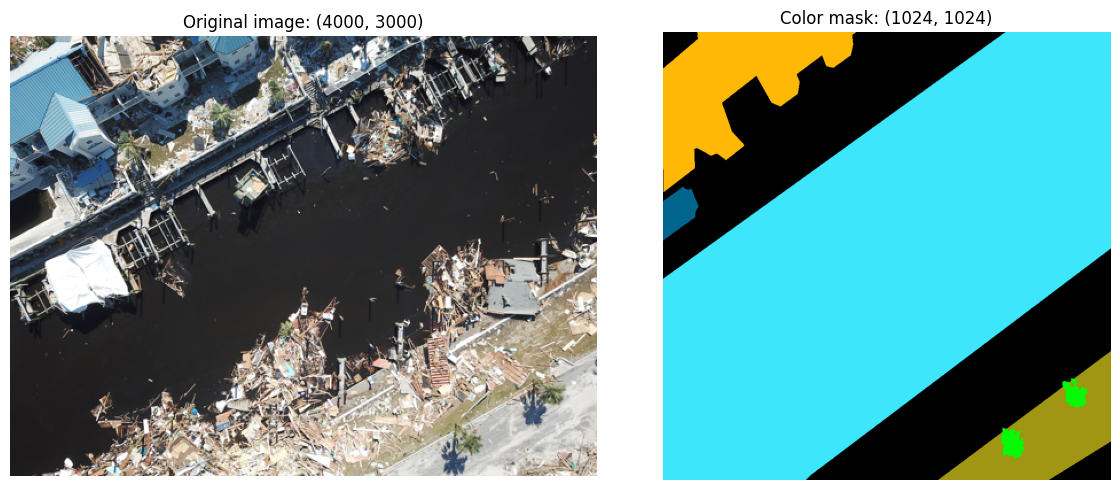

Unique RGB colors: 6
Most common colors: [((np.uint8(0), np.uint8(0), np.uint8(0)), np.int64(273665)), ((np.uint8(0), np.uint8(101), np.uint8(140)), np.int64(6257)), ((np.uint8(4), np.uint8(250), np.uint8(7)), np.int64(5058)), ((np.uint8(61), np.uint8(230), np.uint8(250)), np.int64(642207)), ((np.uint8(160), np.uint8(150), np.uint8(20)), np.int64(47182)), ((np.uint8(255), np.uint8(184), np.uint8(6)), np.int64(74207))]


In [3]:

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

img_path = IMG_DIR / "10778.jpg"
mask_path = MASK_DIR / "10778_lab.png"

img = Image.open(img_path).convert("RGB")
mask = Image.open(mask_path).convert("RGB")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(img.resize((512, 384)))
ax[0].set_title(f"Original image: {img.size}")
ax[0].axis("off")

ax[1].imshow(mask)
ax[1].set_title(f"Color mask: {mask.size}")
ax[1].axis("off")

plt.tight_layout()
plt.show()

colors, counts = np.unique(
    np.array(mask).reshape(-1, 3), axis=0, return_counts=True
)
print("Unique RGB colors:", len(colors))
print("Most common colors:", list(zip(map(tuple, colors[:20]), counts[:20])))


In [4]:

!git clone --depth 1 https://github.com/BinaLab/RescueNet-A-High-Resolution-Post-Disaster-UAV-Dataset-for-Semantic-Segmentation.git /content/RescueNet-official 2>/dev/null || true

from pathlib import Path

repo = Path("/content/RescueNet-official")
for p in repo.rglob("*.py"):
    try:
        text = p.read_text(errors="ignore")
        if "color_encoding" in text or "Building No Damage" in text:
            print(f"\n--- {p.relative_to(repo)} ---")
            for i, line in enumerate(text.splitlines(), 1):
                if any(k in line.lower() for k in [
                    "color_encoding", "background", "building no damage",
                    "building minor damage", "road-clear", "road-blocked"
                ]):
                    print(f"{i}: {line.strip()}")
    except Exception:
        pass



--- Segmentation-Experiments/test.py ---
128: class_encoding = train_set.color_encoding

--- Segmentation-Experiments/data/rescuenet.py ---
4: Classes are: {'Background':0, 'Water':1, 'Building_No_Damage':2, 'Building_Minor_Damage':3, 'Building_Major_Damage':4, 'Building_Total_Destruction':5,
5: 'Vehicle':6, 'Road-Clear':7, 'Road-Blocked':8, 'Tree':9, 'Pool':10}
58: color_encoding = OrderedDict([
66: ('road-clear', (140, 140, 140)),
67: ('road-blocked', (160, 150, 20)),


In [5]:

from pathlib import Path

repo = Path("/content/RescueNet-official")
dataset_file = repo / "Segmentation-Experiments/data/rescuenet.py"

lines = dataset_file.read_text().splitlines()

print("=== OFFICIAL CLASS AND COLOR MAPPING ===")
for i in range(0, min(len(lines), 85)):
    if i < 75:
        print(f"{i+1}: {lines[i]}")

print("\n=== IMAGE/MASK PREPROCESSING ===")
for i, line in enumerate(lines):
    if "__getitem__" in line or "resize" in line.lower() or "transform" in line.lower():
        start, end = max(0, i-2), min(len(lines), i+7)
        print(f"\nLines {start+1}-{end}:")
        for j in range(start, end):
            print(f"{j+1}: {lines[j]}")


=== OFFICIAL CLASS AND COLOR MAPPING ===
1: '''
2: Masks are generated by my own scritps. Mask of all classes in uint8 format means multi hot encoded. 
3: This script tries to segment all types of classes.
4: Classes are: {'Background':0, 'Water':1, 'Building_No_Damage':2, 'Building_Minor_Damage':3, 'Building_Major_Damage':4, 'Building_Total_Destruction':5, 
5:             'Vehicle':6, 'Road-Clear':7, 'Road-Blocked':8, 'Tree':9, 'Pool':10}
6: '''
7: 
8: import os
9: from collections import OrderedDict
10: import torch.utils.data as data
11: from . import utils
12: # @ sh:add
13: from PIL import Image, ImageOps, ImageFilter
14: from torchvision import transforms
15: import numpy as np
16: 
17: 
18: class RescueNet(data.Dataset):
19:     """RescueNet-v2.0 dataset: ....
20: 
21:     Keyword arguments:
22:     - root_dir (``string``): Root directory path.
23:     - mode (``string``): The type of dataset: 'train' for training set, 'val'
24:     for validation set, and 'test' for test set.
2

In [6]:

from pathlib import Path

p = Path("/content/RescueNet-official/Segmentation-Experiments/data/rescuenet.py")
lines = p.read_text().splitlines()

print("=== CLASS PALETTE ===")
print("\n".join(f"{i+1}: {line}" for i, line in enumerate(lines[0:75]) if 0 <= i < 75))

print("\n=== DATASET LOADING ===")
for i, line in enumerate(lines):
    if "def __getitem__" in line:
        print("\n".join(f"{j+1}: {lines[j]}" for j in range(i, min(i+35, len(lines)))))
        break


=== CLASS PALETTE ===
1: '''
2: Masks are generated by my own scritps. Mask of all classes in uint8 format means multi hot encoded. 
3: This script tries to segment all types of classes.
4: Classes are: {'Background':0, 'Water':1, 'Building_No_Damage':2, 'Building_Minor_Damage':3, 'Building_Major_Damage':4, 'Building_Total_Destruction':5, 
5:             'Vehicle':6, 'Road-Clear':7, 'Road-Blocked':8, 'Tree':9, 'Pool':10}
6: '''
7: 
8: import os
9: from collections import OrderedDict
10: import torch.utils.data as data
11: from . import utils
12: # @ sh:add
13: from PIL import Image, ImageOps, ImageFilter
14: from torchvision import transforms
15: import numpy as np
16: 
17: 
18: class RescueNet(data.Dataset):
19:     """RescueNet-v2.0 dataset: ....
20: 
21:     Keyword arguments:
22:     - root_dir (``string``): Root directory path.
23:     - mode (``string``): The type of dataset: 'train' for training set, 'val'
24:     for validation set, and 'test' for test set.
25:     - transform 

In [7]:

from pathlib import Path

repo = Path("/content/RescueNet-official")
for filename in ["Segmentation-Experiments/data/utils.py",
                 "Segmentation-Experiments/data/rescuenet.py"]:
    p = repo / filename
    print(f"\n===== {filename} =====")
    lines = p.read_text().splitlines()

    if filename.endswith("utils.py"):
        for i, line in enumerate(lines):
            if any(k in line.lower() for k in ["def remap", "def default_loader", "def loader"]):
                print("\n".join(f"{j+1}: {lines[j]}"
                                for j in range(i, min(i+25, len(lines)))))
    else:
        print("\n".join(f"{i+1}: {line}"
                        for i, line in enumerate(lines[165:185], 165)))



===== Segmentation-Experiments/data/utils.py =====
69: def remap(image, old_values, new_values):
70:     assert isinstance(image, Image.Image) or isinstance(
71:         image, np.ndarray), "image must be of type PIL.Image or numpy.ndarray"
72:     assert type(new_values) is tuple, "new_values must be of type tuple"
73:     assert type(old_values) is tuple, "old_values must be of type tuple"
74:     assert len(new_values) == len(
75:         old_values), "new_values and old_values must have the same length"
76: 
77:     # If image is a PIL.Image convert it to a numpy array
78:     if isinstance(image, Image.Image):
79:         image = np.array(image)
80: 
81:     # Replace old values by the new ones
82:     tmp = np.zeros_like(image)
83:     for old, new in zip(old_values, new_values):
84:         # Since tmp is already initialized as zeros we can skip new values
85:         # equal to 0
86:         if new != 0:
87:             tmp[image == old] = new
88: 
89:     return Image.fromarr

In [14]:

import random
import numpy as np
import torch
from PIL import Image
from pathlib import Path
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

ROOT = Path("/content/drive/MyDrive/RescueNet-Subset")
IMG_DIR, MASK_DIR = ROOT / "images", ROOT / "masks"
SIZE = 256

# Official RGB palette -> class ID
palette = {
    (0, 0, 0): 0,
    (61, 230, 250): 1,
    (180, 120, 120): 2,
    (235, 255, 7): 3,
    (255, 184, 6): 4,
    (255, 0, 0): 5,
    (255, 0, 245): 6,
    (140, 140, 140): 7,
    (160, 150, 20): 8,
    (4, 250, 7): 9,
    (255, 235, 0): 10,
}

images = {p.stem: p for p in IMG_DIR.iterdir()
          if p.suffix.lower() in [".jpg", ".jpeg", ".png"]}
masks = {p.stem.removesuffix("_lab"): p
         for p in MASK_DIR.glob("*_lab.png")}
pairs = sorted([(images[k], masks[k]) for k in images.keys() & masks.keys()])

class RescueNetSubset(Dataset):
    def __len__(self):
        return len(pairs)


    def __getitem__(self, idx):
      img_path, mask_path = pairs[idx]

      # Load original image
      image = Image.open(img_path).convert("RGB")

      # Temporary central-square crop assumption
      w, h = image.size
      side = min(w, h)
      left = (w - side) // 2
      top = (h - side) // 2

      image = image.crop((left, top, left + side, top + side))
      image = image.resize((SIZE, SIZE), Image.Resampling.BILINEAR)

      # Convert RGB mask colors to class IDs
      rgb_mask = np.array(
          Image.open(mask_path).convert("RGB")
      )

      # 255 means ignore this pixel during training
      label = np.full(rgb_mask.shape[:2], 255, dtype=np.uint8)

      for rgb, class_id in palette.items():
          match = np.all(rgb_mask == rgb, axis=-1)
          label[match] = class_id

      label = Image.fromarray(label).resize(
          (SIZE, SIZE), Image.Resampling.NEAREST
      )

      image = transforms.ToTensor()(image)
      label = torch.from_numpy(
          np.array(label, dtype=np.int64)
      )

      return image, label


dataset = RescueNetSubset()
train_n = int(0.8 * len(dataset))
val_n = len(dataset) - train_n
generator = torch.Generator().manual_seed(42)
train_ds, val_ds = random_split(
    dataset, [train_n, val_n], generator=generator
)

train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, num_workers=2)

print(f"Matched pairs: {len(dataset)}")
print(f"Training: {len(train_ds)} | Validation: {len(val_ds)}")
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")


Matched pairs: 100
Training: 80 | Validation: 20
Device: CUDA


In [9]:

import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, num_classes=11):
        super().__init__()
        self.enc1 = DoubleConv(3, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(128, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.out = nn.Conv2d(32, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNet(num_classes=11).to(device)

print("U-Net initialized on:", device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


U-Net initialized on: cuda
Trainable parameters: 1928747


In [16]:

import copy
import torch.optim as optim

criterion = nn.CrossEntropyLoss(ignore_index=255)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 10

best_val_loss = float("inf")
history = {"train_loss": [], "val_loss": []}

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * imgs.size(0)

    train_loss /= len(train_loader.dataset)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            loss = criterion(model(imgs), labels)
            val_loss += loss.item() * imgs.size(0)

    val_loss /= len(val_loader.dataset)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
          f"Train loss: {train_loss:.4f} | "
          f"Validation loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "/content/rescuenet_unet_best.pth")

print("\nTraining complete. Best checkpoint saved.")


AcceleratorError: CUDA error: device-side assert triggered
Search for `cudaErrorAssert' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [11]:

import numpy as np
from PIL import Image
from collections import Counter

mask_path = MASK_DIR / "10922_lab.png"
arr = np.array(Image.open(mask_path).convert("RGB"))

palette_colors = set(palette.keys())
pixels = arr.reshape(-1, 3)
counts = Counter(map(tuple, pixels))

unknown = [(rgb, count) for rgb, count in counts.items()
           if rgb not in palette_colors]

print("Total unique colors:", len(counts))
print("Unknown colors:", len(unknown))
print("\nMost frequent unknown colors:")
for rgb, count in sorted(unknown, key=lambda x: -x[1])[:25]:
    print(f"RGB {rgb}: {count:,} pixels")


Total unique colors: 6
Unknown colors: 1

Most frequent unknown colors:
RGB (np.uint8(0), np.uint8(101), np.uint8(140)): 10,536 pixels


In [12]:
from collections import Counter, defaultdict
import numpy as np
from PIL import Image

color_counts = Counter()
color_files = defaultdict(list)

for mask_path in MASK_DIR.glob("*_lab.png"):
    arr = np.array(Image.open(mask_path).convert("RGB"))
    colors, counts = np.unique(
        arr.reshape(-1, 3), axis=0, return_counts=True
    )

    for rgb, count in zip(colors, counts):
        color = tuple(map(int, rgb))
        if color not in palette:
            color_counts[color] += int(count)
            color_files[color].append(mask_path.name)

print("Colors missing from palette across all masks:")
for color, count in color_counts.most_common():
    print(f"RGB {color}: {count:,} pixels in {len(color_files[color])} masks")
    print("Example files:", color_files[color][:10])

Colors missing from palette across all masks:
RGB (0, 101, 140): 120,853 pixels in 14 masks
Example files: ['10778_lab.png', '10873_lab.png', '10874_lab.png', '10843_lab.png', '10918_lab.png', '10920_lab.png', '10875_lab.png', '10921_lab.png', '10841_lab.png', '10889_lab.png']


In [13]:

import numpy as np

unknown_rgb = np.array([0, 101, 140])

for rgb, class_id in palette.items():
    distance = np.linalg.norm(unknown_rgb - np.array(rgb))
    print(
        f"Class {class_id:2}: RGB {rgb} | "
        f"Color distance: {distance:.2f}"
    )


Class  0: RGB (0, 0, 0) | Color distance: 172.63
Class  1: RGB (61, 230, 250) | Color distance: 180.17
Class  2: RGB (180, 120, 120) | Color distance: 182.10
Class  3: RGB (235, 255, 7) | Color distance: 310.85
Class  4: RGB (255, 184, 6) | Color distance: 299.78
Class  5: RGB (255, 0, 0) | Color distance: 307.94
Class  6: RGB (255, 0, 245) | Color distance: 293.69
Class  7: RGB (140, 140, 140) | Color distance: 145.33
Class  8: RGB (160, 150, 20) | Color distance: 205.92
Class  9: RGB (4, 250, 7) | Color distance: 199.76
Class 10: RGB (255, 235, 0) | Color distance: 320.28


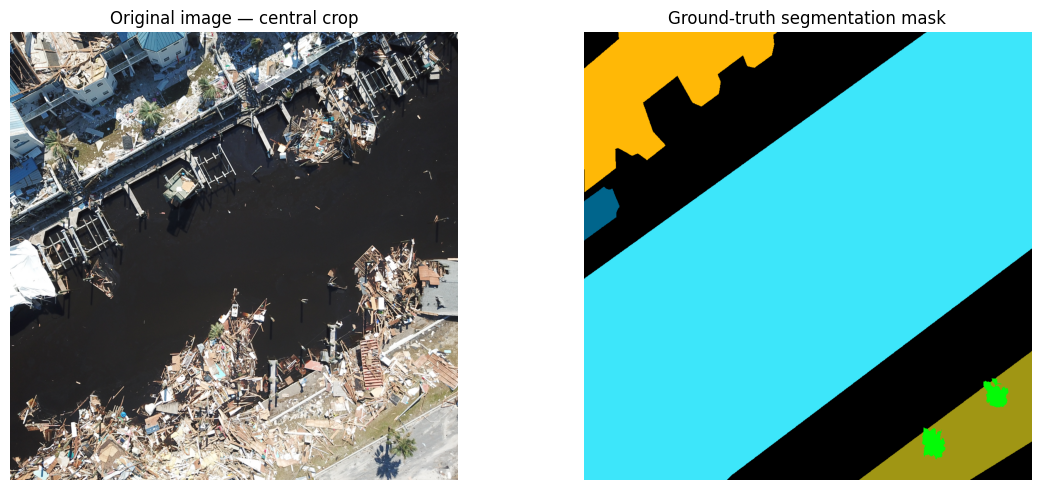

In [17]:

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

img = Image.open(IMG_DIR / "10778.jpg").convert("RGB")
mask = Image.open(MASK_DIR / "10778_lab.png").convert("RGB")

w, h = img.size
side = min(w, h)
left, top = (w - side) // 2, (h - side) // 2

crop = img.crop((left, top, left + side, top + side))
crop = crop.resize(mask.size)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(crop)
plt.title("Original image — central crop")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask)
plt.title("Ground-truth segmentation mask")
plt.axis("off")

plt.tight_layout()
plt.show()


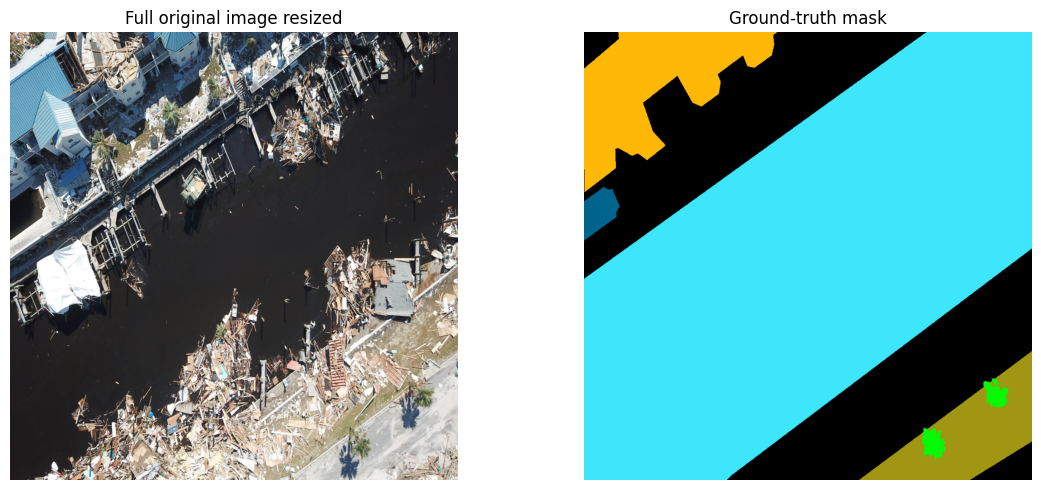

In [18]:

import matplotlib.pyplot as plt
from PIL import Image

img = Image.open(IMG_DIR / "10778.jpg").convert("RGB")
mask = Image.open(MASK_DIR / "10778_lab.png").convert("RGB")

img_resized = img.resize(mask.size, Image.Resampling.BILINEAR)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_resized)
plt.title("Full original image resized")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask)
plt.title("Ground-truth mask")
plt.axis("off")

plt.tight_layout()
plt.show()


In [19]:

from pathlib import Path

repo = Path("/content/RescueNet-official/Segmentation-Experiments/data")

print("Files in official data directory:")
for p in repo.iterdir():
    print(p.name)

print("\nDataset loader references:")
loader_file = repo / "rescuenet.py"
lines = loader_file.read_text().splitlines()

for i, line in enumerate(lines):
    if any(term in line.lower() for term in [
        "train_folder", "train_lbl_folder",
        "loader(", "resize", "crop",
        "org_img_extension", "lbl_img_extension"
    ]):
        start = max(0, i - 2)
        end = min(len(lines), i + 4)
        print(f"\n--- lines {start+1}-{end} ---")
        print("\n".join(
            f"{j+1}: {lines[j]}" for j in range(start, end)
        ))


Files in official data directory:
rescuenet.py
utils.py
__init__.py

Dataset loader references:

--- lines 32-37 ---
32:     """
33:     # Training dataset root folders
34:     train_folder = "train/train-org-img/"
35:     train_lbl_folder = "train/train-label-img/"
36: 
37:     # Validation dataset root folders

--- lines 33-38 ---
33:     # Training dataset root folders
34:     train_folder = "train/train-org-img/"
35:     train_lbl_folder = "train/train-label-img/"
36: 
37:     # Validation dataset root folders
38:     val_folder = "val/val-org-img/"

--- lines 44-49 ---
44: 
45:     # Filters to find the images
46:     org_img_extension = '.jpg'
47:     #lbl_name_filter = '.png'
48: 
49:     lbl_img_extension = '.png'

--- lines 47-52 ---
47:     #lbl_name_filter = '.png'
48: 
49:     lbl_img_extension = '.png'
50:     lbl_name_filter = 'lab'
51: 
52:     # The values associated with the 35 classes

--- lines 88-93 ---
88:             # Get the training data and labels filepaths
89

In [20]:

from pathlib import Path

base = Path("/content/RescueNet-official/Segmentation-Experiments/data")

for filename in ["rescuenet.py", "utils.py"]:
    path = base / filename
    lines = path.read_text().splitlines()

    print(f"\n{'='*20} {filename} {'='*20}")

    for i, line in enumerate(lines):
        if any(word in line.lower() for word in [
            "def loader", "def get_files", "def __getitem__",
            "open(", "resize(", "crop(", "label_path",
            "data_path", "sort("
        ]):
            start = max(0, i - 3)
            end = min(len(lines), i + 12)
            print(f"\n--- lines {start+1}-{end} ---")
            print("\n".join(
                f"{j+1}: {lines[j]}" for j in range(start, end)
            ))



==================== rescuenet.py ====================

--- lines 135-149 ---
135:         image /= self.std
136:         return image
137:         
138:     def __getitem__(self, index):
139:         """
140:         Args:
141:         - index (``int``): index of the item in the dataset
142: 
143:         Returns:
144:         A tuple of ``PIL.Image`` (image, label) where label is the ground-truth
145:         of the image.
146: 
147:         """
148:         
149:         if self.mode == 'vis':

--- lines 147-161 ---
147:         """
148:         
149:         if self.mode == 'vis':
150:             img = Image.open(self.test_data[index]).convert('RGB')
151:             if self.transform is not None:
152:                 img = self.transform(img)
153:             return self.normalize(img), os.path.basename(self.test_data[index])
154:         
155:         if self.mode.lower() == 'train':
156:             data_path, label_path = self.train_data[index], self.train_labels[
157:       

In [21]:

from PIL import Image
from pathlib import Path

img_path = IMG_DIR / "10778.jpg"
mask_path = MASK_DIR / "10778_lab.png"

print("IMAGE")
with Image.open(img_path) as im:
    print("Size:", im.size, "| Mode:", im.mode)

print("\nMASK")
with Image.open(mask_path) as im:
    print("Size:", im.size, "| Mode:", im.mode)

print("\nFilename match:",
      img_path.stem == mask_path.stem.removesuffix("_lab"))

print("\nOfficial loader:")
print("The loader opens both files without cropping or resizing.")


IMAGE
Size: (4000, 3000) | Mode: RGB

MASK
Size: (1024, 1024) | Mode: RGB

Filename match: True

Official loader:
The loader opens both files without cropping or resizing.


In [2]:

import torch
import numpy as np
from pathlib import Path
from PIL import Image

IMAGE_DIR = Path("/content/drive/MyDrive/RescueNet-Subset/images")
MASK_DIR = Path("/content/drive/MyDrive/RescueNet-Subset/masks")

PALETTE = {
    (0, 0, 0): 0,
    (61, 230, 250): 1,
    (180, 120, 120): 2,
    (235, 255, 7): 3,
    (255, 184, 6): 4,
    (255, 0, 0): 5,
    (255, 0, 245): 6,
    (140, 140, 140): 7,
    (160, 150, 20): 8,
    (4, 250, 7): 9,
    (255, 235, 0): 10
}

IGNORE_INDEX = 255
NUM_CLASSES = 11

mask_path = MASK_DIR / "10778_lab.png"
mask_rgb = np.asarray(Image.open(mask_path).convert("RGB"))
labels = np.full(mask_rgb.shape[:2], IGNORE_INDEX, dtype=np.int64)

for rgb, class_id in PALETTE.items():
    labels[np.all(mask_rgb == rgb, axis=-1)] = class_id

print("Label values found:", np.unique(labels))
print("Minimum label:", labels.min())
print("Maximum label:", labels.max())

assert np.all(
    (labels == IGNORE_INDEX) |
    ((labels >= 0) & (labels < NUM_CLASSES))
), "Invalid class ID found!"

print("Mask labels are within the permitted range.")
print("CUDA available:", torch.cuda.is_available())


Label values found: [  0   1   4   8   9 255]
Minimum label: 0
Maximum label: 255
Mask labels are within the permitted range.
CUDA available: True


In [4]:

NUM_CLASSES = 11
IGNORE_INDEX = 255
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model = UNet(NUM_CLASSES).to(DEVICE)
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print("Model initialized successfully on", DEVICE)


NameError: name 'UNet' is not defined

In [3]:

# Recreate the model and optimizer after the runtime restart
model = UNet(NUM_CLASSES).to(DEVICE)
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print("Model initialized on", DEVICE)


NameError: name 'UNet' is not defined

In [1]:

from collections import Counter
from PIL import Image
import numpy as np

print("Checking first 10 matched pairs:\n")

for img_path, mask_path in pairs[:10]:
    with Image.open(img_path) as im:
        img_size = im.size

    with Image.open(mask_path) as im:
        mask_arr = np.array(im.convert("RGB"))
        mask_size = im.size

    colors, counts = np.unique(
        mask_arr.reshape(-1, 3), axis=0, return_counts=True
    )

    print(
        f"{img_path.name:12} image={img_size} "
        f"mask={mask_size} unique_colors={len(colors)}"
    )

print("\nImage dimensions across subset:")
print(Counter(Image.open(p).size for p, _ in pairs))

print("\nMask dimensions across subset:")
print(Counter(Image.open(p).size for _, p in pairs))


Checking first 10 matched pairs:



NameError: name 'pairs' is not defined

Images found: 100
Masks found: 100
Matching filename pairs: 100

10778
Image dimensions: (4000, 3000)
Mask dimensions: (1024, 1024)
Unique mask colours: 6


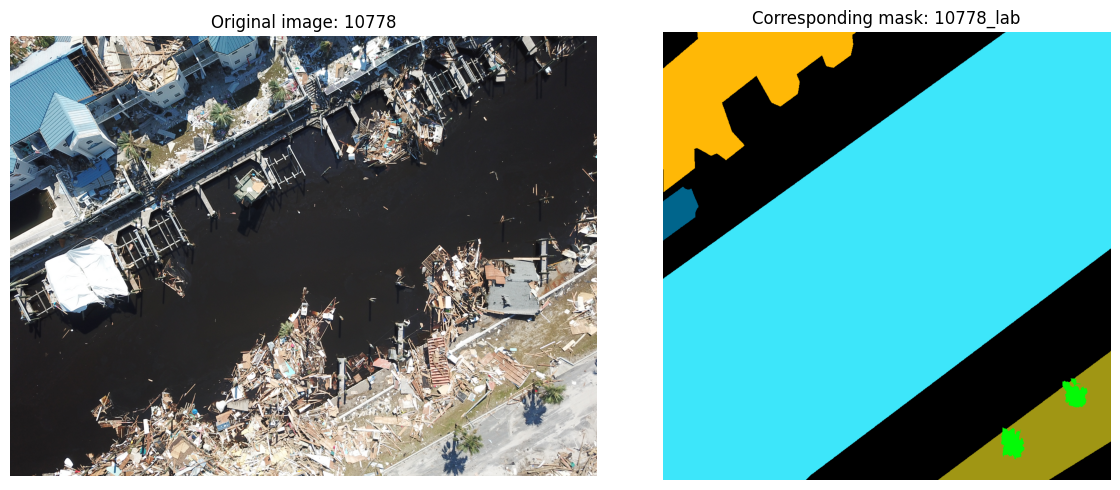


10779
Image dimensions: (4000, 3000)
Mask dimensions: (1024, 1024)
Unique mask colours: 7


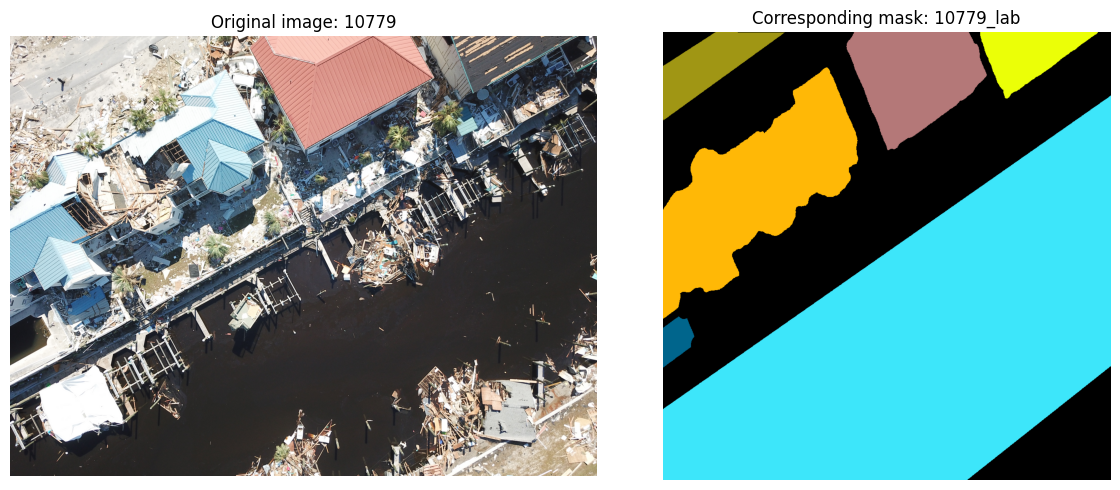


10780
Image dimensions: (4000, 3000)
Mask dimensions: (1024, 1024)
Unique mask colours: 8


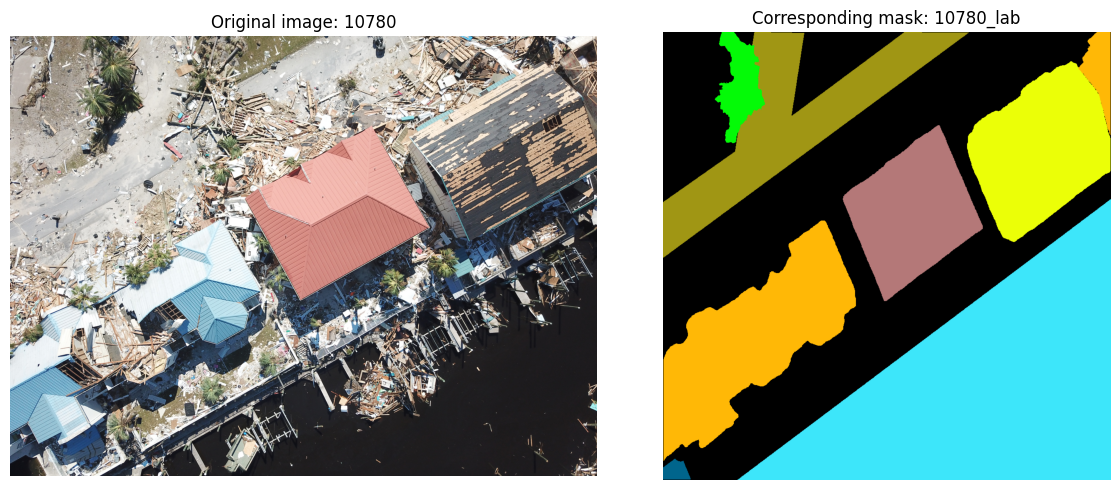

In [23]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Your existing dataset paths
IMAGE_DIR = Path("/content/drive/MyDrive/RescueNet-Subset/images")
MASK_DIR = Path("/content/drive/MyDrive/RescueNet-Subset/masks")

# Match each image to its mask using the filename
images = {p.stem: p for p in IMAGE_DIR.iterdir()
          if p.suffix.lower() in [".jpg", ".jpeg", ".png"]}
masks = {p.stem.replace("_lab", ""): p for p in MASK_DIR.iterdir()
         if p.suffix.lower() == ".png"}

common = sorted(set(images) & set(masks))

print("Images found:", len(images))
print("Masks found:", len(masks))
print("Matching filename pairs:", len(common))

if not common:
    raise ValueError("No matching filenames found. Check the folder paths.")

# Inspect the first three matching pairs
for name in common[:3]:
    image = Image.open(images[name]).convert("RGB")
    mask = Image.open(masks[name]).convert("RGB")

    print(f"\n{name}")
    print("Image dimensions:", image.size)
    print("Mask dimensions:", mask.size)
    print("Unique mask colours:", len(np.unique(
        np.array(mask).reshape(-1, 3), axis=0
    )))

    # Show the original and mask side by side
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(image)
    ax[0].set_title(f"Original image: {name}")
    ax[1].imshow(mask)
    ax[1].set_title(f"Corresponding mask: {name}_lab")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()


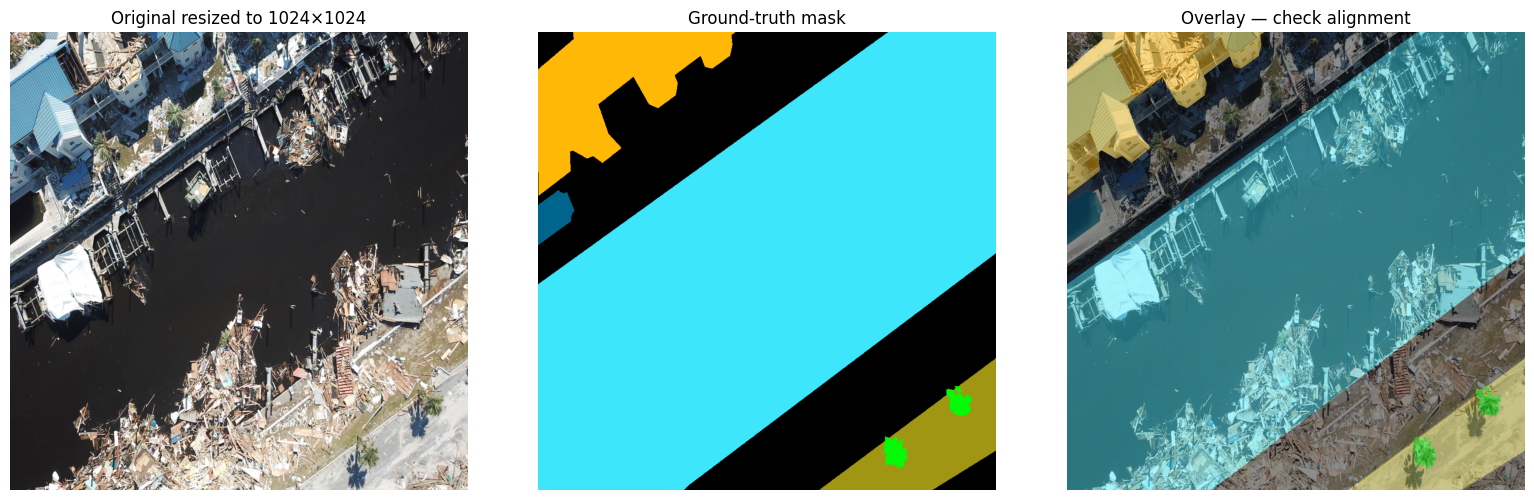

In [24]:

from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

name = "10778"

image_path = f"/content/drive/MyDrive/RescueNet-Subset/images/{name}.jpg"
mask_path = f"/content/drive/MyDrive/RescueNet-Subset/masks/{name}_lab.png"

image = Image.open(image_path).convert("RGB")
mask = Image.open(mask_path).convert("RGB")

# Resize only for a preliminary visual check
image_resized = image.resize(mask.size, Image.Resampling.BILINEAR)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(image_resized)
ax[0].set_title("Original resized to 1024×1024")

ax[1].imshow(mask)
ax[1].set_title("Ground-truth mask")

ax[2].imshow(image_resized)
ax[2].imshow(mask, alpha=0.45)
ax[2].set_title("Overlay — check alignment")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


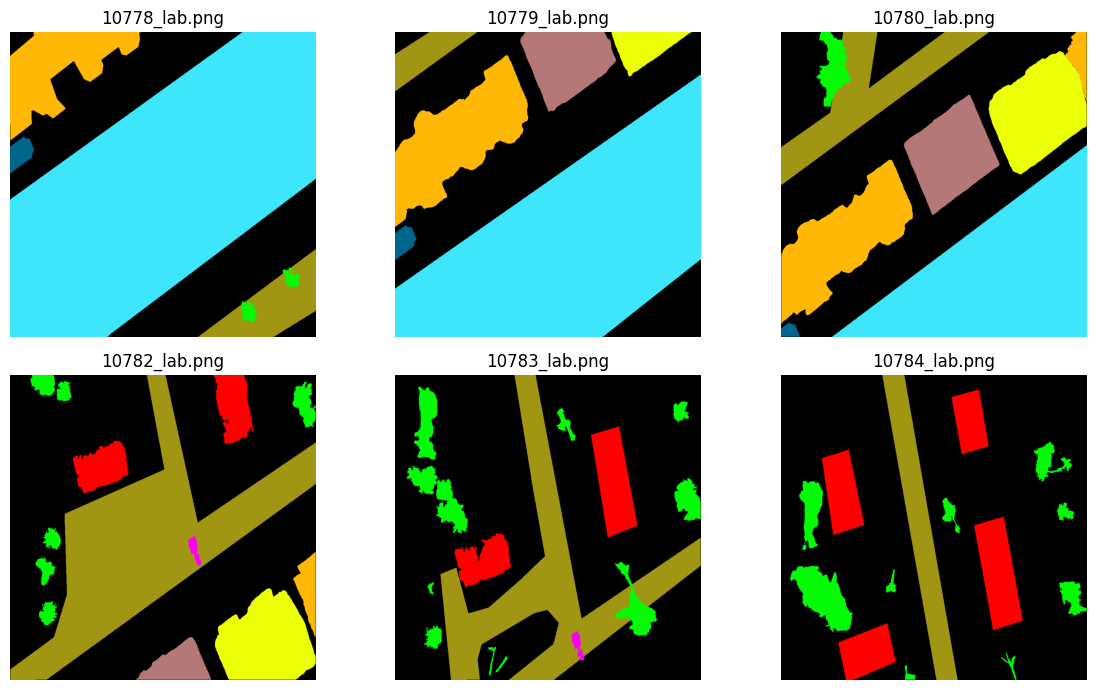

In [25]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

IMAGE_DIR = Path("/content/drive/MyDrive/RescueNet-Subset/images")
MASK_DIR = Path("/content/drive/MyDrive/RescueNet-Subset/masks")

image = Image.open(IMAGE_DIR / "10778.jpg").convert("RGB")
image = image.resize((512, 384))

# Compare the image with several masks, without claiming they are matches
mask_files = sorted(MASK_DIR.glob("*.png"))[:6]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, path in zip(axes.flat, mask_files):
    mask = Image.open(path).convert("RGB")
    ax.imshow(mask)
    ax.set_title(path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [26]:

import os
import random
import numpy as np
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torchvision.transforms import InterpolationMode

# Paths
IMAGE_DIR = Path("/content/drive/MyDrive/RescueNet-Subset/images")
MASK_DIR = Path("/content/drive/MyDrive/RescueNet-Subset/masks")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Training device:", DEVICE)

# RescueNet RGB color palette
PALETTE = {
    (0, 0, 0): 0,          # Background / unlabeled
    (61, 230, 250): 1,     # Water
    (180, 120, 120): 2,    # Building - no damage
    (235, 255, 7): 3,      # Building - minor/medium damage
    (255, 184, 6): 4,      # Building - major damage
    (255, 0, 0): 5,        # Building - total destruction
    (255, 0, 245): 6,      # Vehicle
    (140, 140, 140): 7,    # Road - clear
    (160, 150, 20): 8,     # Road - blocked
    (4, 250, 7): 9,        # Tree
    (255, 235, 0): 10      # Pool
}

NUM_CLASSES = 11
IMG_SIZE = 256
IGNORE_INDEX = 255

class RescueNetDataset(Dataset):
    def __init__(self, image_dir, mask_dir):
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)

        images = {
            p.stem: p for p in self.image_dir.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        }
        masks = {
            p.stem.replace("_lab", ""): p
            for p in self.mask_dir.glob("*.png")
        }

        self.pairs = [
            (images[k], masks[k])
            for k in sorted(set(images) & set(masks))
        ]
        if not self.pairs:
            raise ValueError("No matching image-mask pairs found.")

        print("Matched pairs:", len(self.pairs))

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        image_path, mask_path = self.pairs[idx]

        # Image is resized to the mask's square geometry before training.
        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("RGB")

        image = image.resize(
            (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
        )
        mask = mask.resize(
            (IMG_SIZE, IMG_SIZE), Image.Resampling.NEAREST
        )

        image = np.asarray(image, dtype=np.float32) / 255.0
        mask_rgb = np.asarray(mask, dtype=np.uint8)

        label = np.full(mask_rgb.shape[:2], IGNORE_INDEX, dtype=np.int64)

        for rgb, class_id in PALETTE.items():
            matches = np.all(mask_rgb == rgb, axis=-1)
            label[matches] = class_id

        image = torch.from_numpy(image).permute(2, 0, 1)
        label = torch.from_numpy(label)

        return image, label

dataset = RescueNetDataset(IMAGE_DIR, MASK_DIR)

# Fixed seed for a reproducible train/validation split
generator = torch.Generator().manual_seed(42)
n_val = max(1, int(0.2 * len(dataset)))
n_train = len(dataset) - n_val

train_ds, val_ds = random_split(
    dataset, [n_train, n_val], generator=generator
)

train_loader = DataLoader(
    train_ds, batch_size=4, shuffle=True, num_workers=2,
    pin_memory=(DEVICE == "cuda")
)
val_loader = DataLoader(
    val_ds, batch_size=4, shuffle=False, num_workers=2,
    pin_memory=(DEVICE == "cuda")
)

print(f"Training samples: {len(train_ds)} | Validation samples: {len(val_ds)}")


Training device: cuda
Matched pairs: 100
Training samples: 80 | Validation samples: 20


In [5]:

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    test = torch.randn(2, 3, device="cuda")
    print("GPU test passed:", test.shape)
else:
    print("Using CPU for now.")


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU test passed: torch.Size([2, 3])


In [29]:

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, num_classes=11):
        super().__init__()
        self.enc1 = DoubleConv(3, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = DoubleConv(512, 256)
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.out = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.out(d1)


model = UNet(NUM_CLASSES).to(DEVICE)

criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print("U-Net initialized successfully.")


AcceleratorError: CUDA error: device-side assert triggered
Search for `cudaErrorAssert' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [28]:

from tqdm.auto import tqdm

EPOCHS = 10
best_val_loss = float("inf")
CHECKPOINT = "/content/drive/MyDrive/rescuenet_unet_best.pth"

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    train_batches = 0

    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        # Skip batches with no recognized labels
        if not torch.any(masks != IGNORE_INDEX):
            continue

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_batches += 1

    model.eval()
    val_loss = 0.0
    val_batches = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            if not torch.any(masks != IGNORE_INDEX):
                continue

            loss = criterion(model(images), masks)
            val_loss += loss.item()
            val_batches += 1

    train_avg = train_loss / max(1, train_batches)
    val_avg = val_loss / max(1, val_batches)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train loss: {train_avg:.4f} | "
        f"Validation loss: {val_avg:.4f}"
    )

    if val_batches > 0 and val_avg < best_val_loss:
        best_val_loss = val_avg
        torch.save(model.state_dict(), CHECKPOINT)
        print("Saved best checkpoint:", CHECKPOINT)

print("Training complete. Best validation loss:", best_val_loss)


Epoch 1/10:   0%|          | 0/20 [00:00<?, ?it/s]

AcceleratorError: Caught AcceleratorError in pin memory thread for device 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/pin_memory.py", line 34, in do_one_step
    data = pin_memory(data, device)
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/pin_memory.py", line 100, in pin_memory
    clone[i] = pin_memory(item, device)
               ~~~~~~~~~~^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/pin_memory.py", line 57, in pin_memory
    return data.pin_memory()
           ~~~~~~~~~~~~~~~^^
torch.AcceleratorError: CUDA error: device-side assert triggered
Search for `cudaErrorAssert' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compi

In [6]:

import torch
import torch.nn as nn

DEVICE = "cuda"
NUM_CLASSES = 11
IGNORE_INDEX = 255

# Initialize a fresh model
model = UNet(num_classes=NUM_CLASSES).to(DEVICE)

criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Verify that the model can run on the GPU
dummy_input = torch.randn(1, 3, 256, 256, device=DEVICE)

with torch.no_grad():
    dummy_output = model(dummy_input)

print("Model initialized successfully!")
print("Output shape:", tuple(dummy_output.shape))
print("Expected shape: (1, 11, 256, 256)")


NameError: name 'UNet' is not defined

In [7]:

import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, num_classes=11):
        super().__init__()

        self.enc1 = DoubleConv(3, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = DoubleConv(512, 256)
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.out = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.out(d1)

print("UNet class defined successfully.")


UNet class defined successfully.


In [8]:

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NUM_CLASSES = 11
IGNORE_INDEX = 255

model = UNet(num_classes=NUM_CLASSES).to(DEVICE)
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

with torch.no_grad():
    output = model(torch.randn(1, 3, 256, 256, device=DEVICE))

print("Model test passed!")
print("Device:", DEVICE)
print("Output shape:", tuple(output.shape))


Model test passed!
Device: cuda
Output shape: (1, 11, 256, 256)


In [9]:

import numpy as np
from pathlib import Path
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader, random_split

IMAGE_DIR = Path("/content/drive/MyDrive/RescueNet-Subset/images")
MASK_DIR = Path("/content/drive/MyDrive/RescueNet-Subset/masks")

IMG_SIZE = 256
NUM_CLASSES = 11
IGNORE_INDEX = 255

PALETTE = {
    (0, 0, 0): 0,
    (61, 230, 250): 1,
    (180, 120, 120): 2,
    (235, 255, 7): 3,
    (255, 184, 6): 4,
    (255, 0, 0): 5,
    (255, 0, 245): 6,
    (140, 140, 140): 7,
    (160, 150, 20): 8,
    (4, 250, 7): 9,
    (255, 235, 0): 10,
}

class RescueNetDataset(Dataset):
    def __init__(self, image_dir, mask_dir):
        images = {
            p.stem: p for p in Path(image_dir).iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        }
        masks = {
            p.stem.replace("_lab", ""): p
            for p in Path(mask_dir).glob("*.png")
        }

        self.pairs = [
            (images[k], masks[k])
            for k in sorted(set(images) & set(masks))
        ]

        if not self.pairs:
            raise ValueError("No matching image-mask pairs found.")

        print("Matched image-mask pairs:", len(self.pairs))

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        image_path, mask_path = self.pairs[idx]

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("RGB")

        image = image.resize(
            (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
        )
        mask = mask.resize(
            (IMG_SIZE, IMG_SIZE), Image.Resampling.NEAREST
        )

        image = np.asarray(image, dtype=np.float32) / 255.0
        mask_rgb = np.asarray(mask, dtype=np.uint8)

        label = np.full(
            mask_rgb.shape[:2], IGNORE_INDEX, dtype=np.int64
        )

        for rgb, class_id in PALETTE.items():
            label[np.all(mask_rgb == rgb, axis=-1)] = class_id

        return (
            torch.from_numpy(image).permute(2, 0, 1),
            torch.from_numpy(label)
        )

dataset = RescueNetDataset(IMAGE_DIR, MASK_DIR)

generator = torch.Generator().manual_seed(42)
val_size = max(1, int(0.2 * len(dataset)))
train_size = len(dataset) - val_size

train_ds, val_ds = random_split(
    dataset, [train_size, val_size], generator=generator
)

train_loader = DataLoader(
    train_ds, batch_size=4, shuffle=True, num_workers=2,
    pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_ds, batch_size=4, shuffle=False, num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))


Matched image-mask pairs: 100
Training samples: 80
Validation samples: 20


In [10]:

images, masks = next(iter(train_loader))

print("Image batch:", images.shape)
print("Mask batch:", masks.shape)
print("Label values:", torch.unique(masks).tolist())

valid = (masks == IGNORE_INDEX) | (
    (masks >= 0) & (masks < NUM_CLASSES)
)
assert valid.all(), "Invalid class ID detected!"

assert (masks != IGNORE_INDEX).any(), "Batch contains no valid labels."

print("Batch validation passed.")


Image batch: torch.Size([4, 3, 256, 256])
Mask batch: torch.Size([4, 256, 256])
Label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 255]
Batch validation passed.


In [11]:

from tqdm.auto import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 10
CHECKPOINT = "/content/drive/MyDrive/rescuenet_unet_best.pth"

model = UNet(num_classes=NUM_CLASSES).to(DEVICE)
criterion = torch.nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

best_val_loss = float("inf")

for epoch in range(EPOCHS):
    model.train()
    train_total = 0.0
    train_steps = 0

    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        if not (masks != IGNORE_INDEX).any():
            continue

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        train_total += loss.item()
        train_steps += 1

    model.eval()
    val_total = 0.0
    val_steps = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            if not (masks != IGNORE_INDEX).any():
                continue

            loss = criterion(model(images), masks)
            val_total += loss.item()
            val_steps += 1

    train_loss = train_total / max(train_steps, 1)
    val_loss = val_total / max(val_steps, 1)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

    if val_steps and val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), CHECKPOINT)
        print("Best model checkpoint saved.")

print("Training finished.")
print("Checkpoint:", CHECKPOINT)


Epoch 1/10:   0%|          | 0/20 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cabe03979c0><function _MultiProcessingDataLoaderIter.__del__ at 0x7cabe03979c0>
Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
self._shutdown_workers()    
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
if w.is_alive():
    if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only te

Epoch 1/10 | Train loss: 2.3302 | Validation loss: 5.3608
Best model checkpoint saved.


Epoch 2/10:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 2/10 | Train loss: 1.8879 | Validation loss: 3.6805
Best model checkpoint saved.


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cabe03979c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cabe03979c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 9/10 | Train loss: 1.0599 | Validation loss: 1.0721
Best model checkpoint saved.


Epoch 10/10:   0%|          | 0/20 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cabe03979c0>
Exception ignored in: Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7cabe03979c0>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    Traceback (most recent call last):
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        if w.is_alive():
assert self._parent_pid == os.getpid(), 'can only test a child process'
  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

Epoch 10/10 | Train loss: 1.0309 | Validation loss: 1.3707
Training finished.
Checkpoint: /content/drive/MyDrive/rescuenet_unet_best.pth


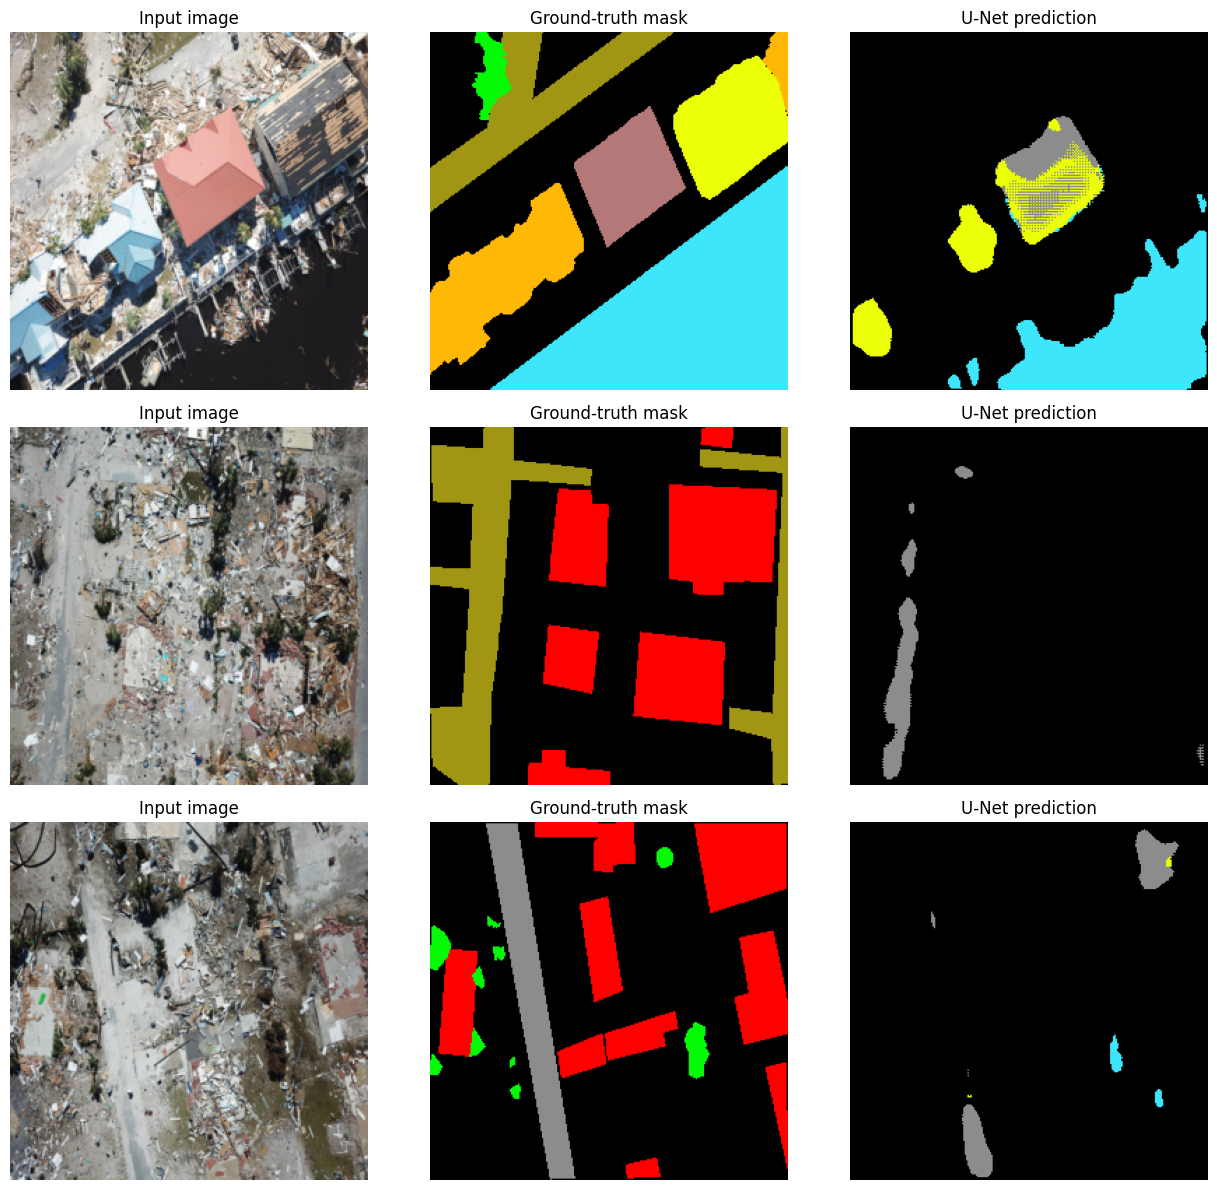

In [12]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CHECKPOINT = "/content/drive/MyDrive/rescuenet_unet_best.pth"

# Load the best model saved during training
model = UNet(num_classes=NUM_CLASSES).to(DEVICE)
model.load_state_dict(
    torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
)
model.eval()

# RescueNet class colors for visualization
COLORS = np.array([
    [0, 0, 0],        # Background / unlabeled
    [61, 230, 250],   # Water
    [180, 120, 120], # Building - no damage
    [235, 255, 7],   # Building - minor damage
    [255, 184, 6],   # Building - major damage
    [255, 0, 0],     # Building - destruction
    [255, 0, 245],   # Vehicle
    [140, 140, 140], # Road - clear
    [160, 150, 20],  # Road - blocked
    [4, 250, 7],     # Tree
    [255, 235, 0],   # Pool
], dtype=np.uint8)

# Show up to 3 validation examples
fig, axes = plt.subplots(3, 3, figsize=(13, 12))

for i in range(min(3, len(val_ds))):
    image, target = val_ds[i]

    with torch.no_grad():
        logits = model(image.unsqueeze(0).to(DEVICE))
        prediction = logits.argmax(dim=1).squeeze(0).cpu().numpy()

    image_np = image.permute(1, 2, 0).numpy()
    target_np = target.numpy()

    # Convert class IDs to colors; ignored pixels are shown in black
    target_vis = np.zeros((*target_np.shape, 3), dtype=np.uint8)
    valid = (target_np >= 0) & (target_np < NUM_CLASSES)
    target_vis[valid] = COLORS[target_np[valid]]

    pred_vis = COLORS[prediction]

    axes[i, 0].imshow(image_np)
    axes[i, 0].set_title("Input image")

    axes[i, 1].imshow(target_vis)
    axes[i, 1].set_title("Ground-truth mask")

    axes[i, 2].imshow(pred_vis)
    axes[i, 2].set_title("U-Net prediction")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [13]:
import torch
import numpy as np

CLASS_NAMES = [
    "Background / unlabeled",
    "Water",
    "Building - no damage",
    "Building - minor damage",
    "Building - major damage",
    "Building - total destruction",
    "Vehicle",
    "Road - clear",
    "Road - blocked",
    "Tree",
    "Pool",
]

NUM_CLASSES = len(CLASS_NAMES)
IGNORE_INDEX = 255

confusion = torch.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=torch.int64,
    device=DEVICE
)

model.eval()

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        predictions = model(images).argmax(dim=1)

        valid = (
            (masks != IGNORE_INDEX)
            & (masks >= 0)
            & (masks < NUM_CLASSES)
        )

        targets = masks[valid]
        preds = predictions[valid]

        confusion += torch.bincount(
            targets * NUM_CLASSES + preds,
            minlength=NUM_CLASSES ** 2
        ).reshape(NUM_CLASSES, NUM_CLASSES)

intersection = confusion.diag()
union = confusion.sum(dim=0) + confusion.sum(dim=1) - intersection

iou = intersection.float() / union.clamp_min(1).float()
present = union > 0

print("CLASS-WISE IoU")
for i, name in enumerate(CLASS_NAMES):
    if present[i]:
        print(f"{name:30s}: {iou[i].item():.4f}")
    else:
        print(f"{name:30s}: Not present")

if present.any():
    print(f"\nMean IoU: {iou[present].mean().item():.4f}")

CLASS-WISE IoU
Background / unlabeled        : 0.6941
Water                         : 0.4968
Building - no damage          : 0.0001
Building - minor damage       : 0.2334
Building - major damage       : 0.0000
Building - total destruction  : 0.0000
Vehicle                       : 0.0000
Road - clear                  : 0.3923
Road - blocked                : 0.0000
Tree                          : 0.0000
Pool                          : Not present

Mean IoU: 0.1817


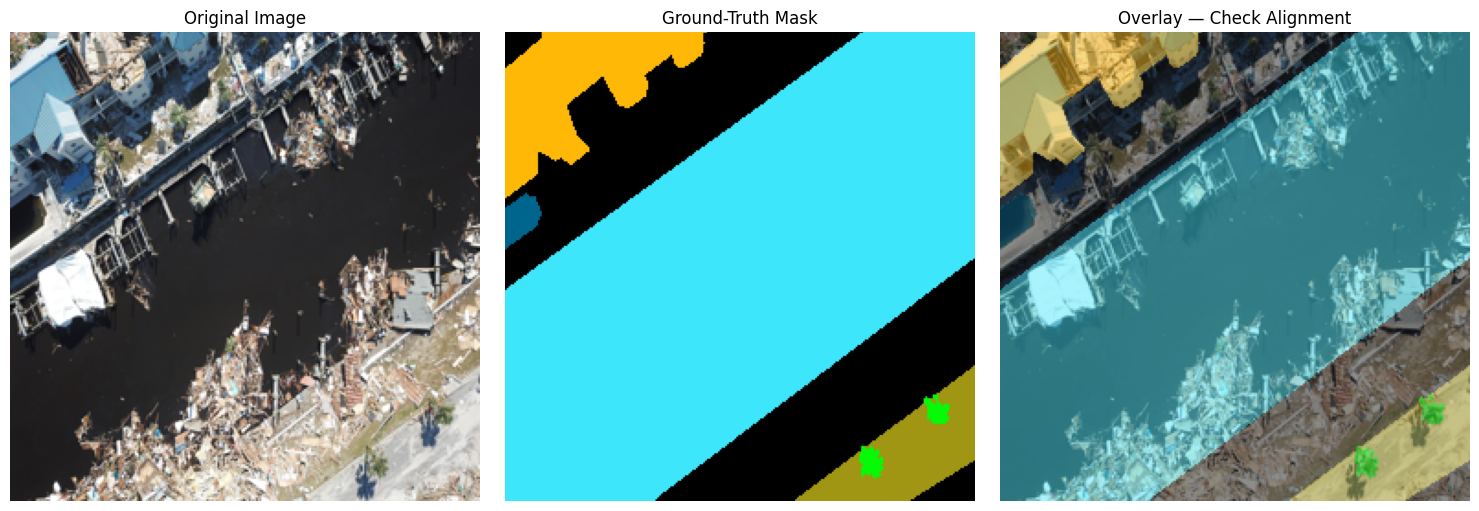

In [14]:
import matplotlib.pyplot as plt
from PIL import Image
import os

image_path = "/content/drive/MyDrive/RescueNet-Subset/images/10778.jpg"
mask_path = "/content/drive/MyDrive/RescueNet-Subset/masks/10778_lab.png"

image = Image.open(image_path).convert("RGB").resize((256, 256))
mask = Image.open(mask_path).convert("RGB").resize(
    (256, 256), resample=Image.Resampling.NEAREST
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(mask)
axes[1].set_title("Ground-Truth Mask")

axes[2].imshow(image)
axes[2].imshow(mask, alpha=0.45)
axes[2].set_title("Overlay — Check Alignment")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
import os

image_dir = "/content/drive/MyDrive/RescueNet-Subset/images"
mask_dir = "/content/drive/MyDrive/RescueNet-Subset/masks"

print("Images:")
print(sorted(os.listdir(image_dir))[:10])

print("\nMasks:")
print(sorted(os.listdir(mask_dir))[:10])

Images:
['10778.jpg', '10779.jpg', '10780.jpg', '10782.jpg', '10783.jpg', '10784.jpg', '10785.jpg', '10786.jpg', '10787.jpg', '10788.jpg']

Masks:
['10778_lab.png', '10779_lab.png', '10780_lab.png', '10782_lab.png', '10783_lab.png', '10784_lab.png', '10785_lab.png', '10786_lab.png', '10787_lab.png', '10788_lab.png']


In [16]:
from PIL import Image
import os

for filename in ["10778", "10779", "10780"]:
    image_path = os.path.join(image_dir, filename + ".jpg")
    mask_path = os.path.join(mask_dir, filename + "_lab.png")

    if os.path.exists(image_path) and os.path.exists(mask_path):
        image = Image.open(image_path)
        mask = Image.open(mask_path)

        print(
            filename,
            "| Image:", image.size,
            "| Mask:", mask.size
        )

10778 | Image: (4000, 3000) | Mask: (1024, 1024)
10779 | Image: (4000, 3000) | Mask: (1024, 1024)
10780 | Image: (4000, 3000) | Mask: (1024, 1024)
